# **Lab Program-05**

Linear egression using Neural Network

Aim: Program to implement neural network model to make predictions using linear regression

Dataset: Real estate dataset

In [ ]:
import pandas as pd
df=pd.read_csv('Real estate.csv')

In [ ]:
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [ ]:
df.isnull().sum()

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [ ]:
df.duplicated().sum()

0

<AxesSubplot:>

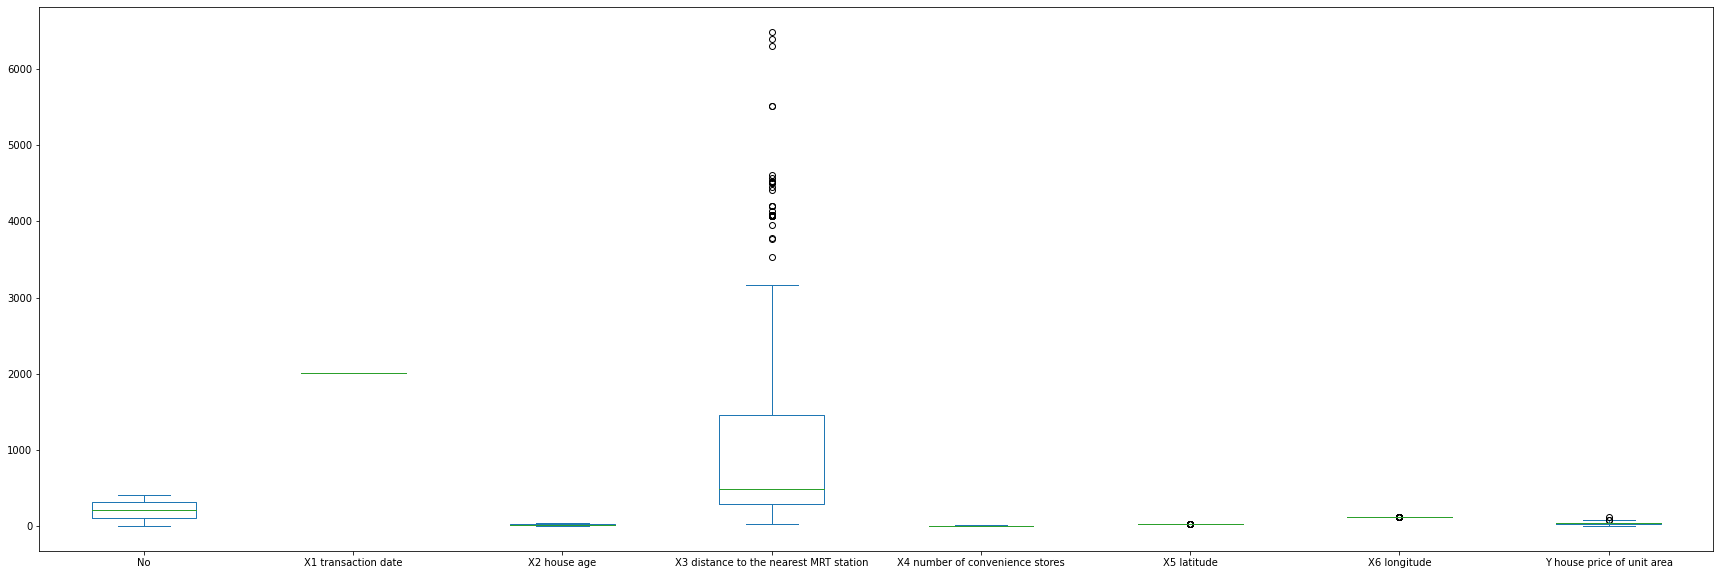

In [ ]:
import matplotlib.pyplot as plt
df.plot.box(figsize=(30,10))

In [ ]:
#Removing Outliers
import seaborn as sns
def outliers(df):
  sns.boxplot(df)
  plt.show()
  import math
  q1=df.quantile(0.25)
  q3=df.quantile(0.75)
  iqr= q3-q1
  upper=math.floor(q3+1.5*iqr)
  lower=math.floor(q3-1.5*iqr)
  return(upper,lower)

In [ ]:
import numpy as np
def remove_outliers(df,upper,lower):
  df=(np.where(df>=upper,upper,df))
  df=(np.where(df<=lower,lower,df))
  sns.boxplot(df)
  plt.show()

/usr/local/lib/python3.8/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


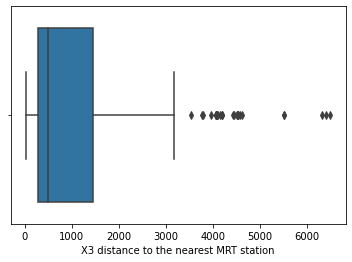

/usr/local/lib/python3.8/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


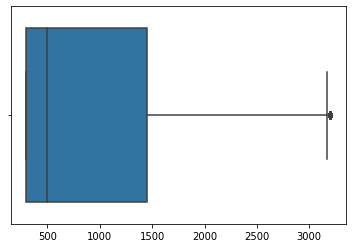

/usr/local/lib/python3.8/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


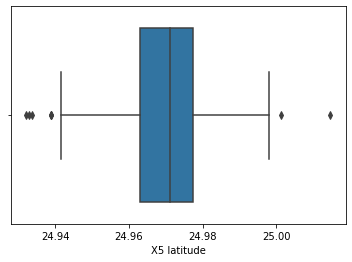

/usr/local/lib/python3.8/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


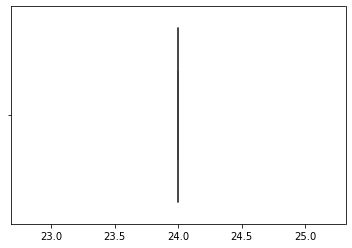

/usr/local/lib/python3.8/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


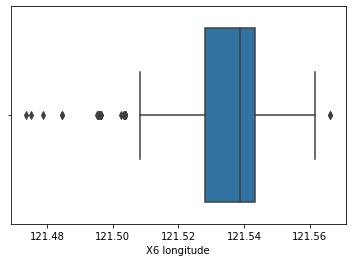

/usr/local/lib/python3.8/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


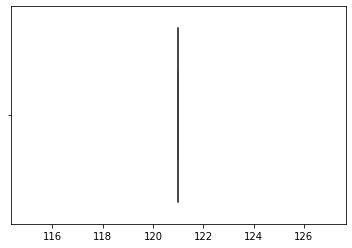

/usr/local/lib/python3.8/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


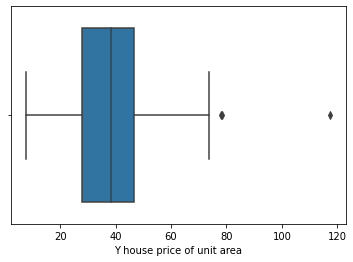

/usr/local/lib/python3.8/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


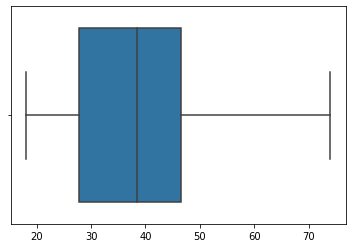

In [ ]:
df1=['X3 distance to the nearest MRT station','X5 latitude','X6 longitude',	'Y house price of unit area']
for i in df1:
  a=outliers(df[i])
  u=a[0]
  l=abs(a[1])
  remove_outliers(df[i],u,l)

In [ ]:
x=df[['X1 transaction date','X2 house age','X3 distance to the nearest MRT station','X4 number of convenience stores','X5 latitude','X6 longitude']]
y=df[['Y house price of unit area']]

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30)

In [ ]:
x_train.shape

(289, 6)

In [ ]:
y_train.shape

(289, 1)

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
model = Sequential()
model.add(Dense(50,activation ='linear'))
model.add(Dense(100,activation='linear'))
model.add(Dense(1,activation='linear'))

In [ ]:
model.compile(loss='mse', optimizer='adam', metrics=['mse'])
l= model.fit(x_train,y_train,epochs=100)

Epoch 1/100
10/10 [==============================] - 2s 6ms/step - loss: 18246.0410 - mse: 18246.0410
Epoch 2/100
10/10 [==============================] - 0s 5ms/step - loss: 4139.2559 - mse: 4139.2559
Epoch 3/100
10/10 [==============================] - 0s 5ms/step - loss: 3447.2964 - mse: 3447.2964
Epoch 4/100
10/10 [==============================] - 0s 5ms/step - loss: 906.5526 - mse: 906.5526
Epoch 5/100
10/10 [==============================] - 0s 5ms/step - loss: 238.1990 - mse: 238.1990
Epoch 6/100
10/10 [==============================] - 0s 5ms/step - loss: 355.9120 - mse: 355.9120
Epoch 7/100
10/10 [==============================] - 0s 4ms/step - loss: 229.3314 - mse: 229.3314
Epoch 8/100
10/10 [==============================] - 0s 4ms/step - loss: 177.4285 - mse: 177.4285
Epoch 9/100
10/10 [==============================] - 0s 5ms/step - loss: 211.9974 - mse: 211.9974
Epoch 10/100
10/10 [==============================] - 0s 5ms/step - loss: 127.7256 - mse: 127.7256
Epoch 11/10

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 50)                350       
                                                                 
 dense_1 (Dense)             (None, 100)               5100      
                                                                 
 dense_2 (Dense)             (None, 1)                 101       
                                                                 
Total params: 5,551
Trainable params: 5,551
Non-trainable params: 0
_________________________________________________________________


In [ ]:
train=model.evaluate(x_train,y_train)
test=model.evaluate(x_test,y_test)

4/4 [==============================] - 0s 4ms/step - loss: 264.5695 - mse: 264.5695


In [ ]:
print("Train loss:",train[0])
print("Train MSE:",train[1])
print("Test loss:",test[0])
print("Test MSE:",test[1])

Train loss: 283.138671875
Train MSE: 283.138671875
Test loss: 264.5694885253906
Test MSE: 264.5694885253906


Conclusion: The linear regression model gave Train MSE has 283.3 and test MSE has 264.569. So, to reduce the model we need to tune the model